## **IMPORTS & DATA INTRO**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import copy
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

In [2]:
df = pd.read_excel("/content/MentalHealthSurvey - Encoded.xlsx")

In [3]:
df.head()

,student_id,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,study_satisfaction,academic_workload,academic_pressure,...,degree_major_Software Engineering,gender_Female,gender_Male,activity_Creative Outlets,activity_Online Entertainment,activity_Outdoor Activities,activity_Religious Activities,activity_Sleep,activity_Social Connections,activity_Sports and Fitness
0,1888,1,4,0,0,0,1,5,4,5,...,0,0,1,0,1,0,1,0,1,0
1,6958,2,3,0,0,1,0,5,5,5,...,0,0,1,0,1,0,1,0,0,1
2,3742,2,3,1,0,0,1,3,5,4,...,0,0,1,0,1,0,0,0,0,0
3,2065,2,4,0,1,0,1,3,5,5,...,0,1,0,0,1,0,0,0,0,0
4,8645,2,4,0,0,0,1,4,5,5,...,0,1,0,0,1,0,1,0,1,0


In [4]:
df.dtypes

,0
student_id,int64
academic_year,int64
cgpa,int64
residential_status,int64
campus_discrimination,int64
sports_engagement,int64
average_sleep,int64
study_satisfaction,int64
academic_workload,int64
academic_pressure,int64


## **STANDARDIZE**

In [5]:
df_clean = df.drop(labels='student_id', axis=1)

# fit and transform using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_clean)

numeric_df_scaled = pd.DataFrame(X_scaled, columns=df_clean.columns)

# Export the scaled dataset

numeric_df_scaled.head()
#numeric_df_scaled.to_csv(r"/content/df_en_scaled.csv", index=False)

,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,study_satisfaction,academic_workload,academic_pressure,financial_concerns,...,degree_major_Software Engineering,gender_Female,gender_Male,activity_Creative Outlets,activity_Online Entertainment,activity_Outdoor Activities,activity_Religious Activities,activity_Sleep,activity_Social Connections,activity_Sports and Fitness
0,0.333333,0.8,0.0,0.0,0.000000,0.5,1.00,0.666667,1.00,0.75,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.666667,0.6,0.0,0.0,0.333333,0.0,1.00,1.000000,1.00,0.50,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
2,0.666667,0.6,1.0,0.0,0.000000,0.5,0.50,1.000000,0.75,0.75,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.666667,0.8,0.0,1.0,0.000000,0.5,0.50,1.000000,1.00,0.25,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.666667,0.8,0.0,0.0,0.000000,0.5,0.75,1.000000,1.00,0.50,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [6]:
#describe final numeric dataset
df_clean.describe()

,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,study_satisfaction,academic_workload,academic_pressure,financial_concerns,...,degree_major_Software Engineering,gender_Female,gender_Male,activity_Creative Outlets,activity_Online Entertainment,activity_Outdoor Activities,activity_Religious Activities,activity_Sleep,activity_Social Connections,activity_Sports and Fitness
count,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,...,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000,83.000000
mean,1.132530,3.638554,0.240964,0.240964,0.879518,1.301205,3.891566,3.879518,3.795181,3.361446,...,0.036145,0.289157,0.710843,0.108434,0.409639,0.228916,0.554217,0.240964,0.373494,0.240964
std,1.068063,1.348697,0.430268,0.430268,1.052263,0.578791,1.047786,0.861049,1.101651,1.375556,...,0.187784,0.456127,0.456127,0.312818,0.494757,0.422689,0.500073,0.430268,0.486672,0.430268
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,3.000000,0.000000,0.000000,0.000000,1.000000,3.000000,3.000000,3.000000,2.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,4.000000,0.000000,0.000000,1.000000,1.000000,4.000000,4.000000,4.000000,3.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,2.000000,5.000000,0.000000,0.000000,1.500000,2.000000,5.000000,4.500000,5.000000,5.000000,...,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,3.000000,5.000000,1.000000,1.000000,3.000000,2.000000,5.000000,5.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## **FEATURE SELECTION**

### KMEANS

In [7]:
numeric_df_scaled.columns

Index(['academic_year', 'cgpa', 'residential_status', 'campus_discrimination',
       'sports_engagement', 'average_sleep', 'study_satisfaction',
       'academic_workload ', 'academic_pressure', 'financial_concerns',
       'social_relationships', 'depression', 'anxiety', 'isolation',
       'future_insecurity', 'degree_major_Computer Science',
       'degree_major_Data Science', 'degree_major_Information Technology',
       'degree_major_Software Engineering', 'gender_Female', 'gender_Male',
       'activity_Creative Outlets', 'activity_Online Entertainment',
       'activity_Outdoor Activities', 'activity_Religious Activities',
       'activity_Sleep', 'activity_Social Connections',
       'activity_Sports and Fitness'],
      dtype='object')

In [8]:
#data_en = df.drop(['student_id', 'gender_Male', 'gender_Female'], axis=1)
data_en = numeric_df_scaled.drop(['degree_major_Computer Science',
       'degree_major_Data Science', 'degree_major_Information Technology',
       'degree_major_Software Engineering', 'gender_Male', 'gender_Female',
        'activity_Creative Outlets', 'activity_Online Entertainment',
       'activity_Outdoor Activities', 'activity_Religious Activities',
       'activity_Sleep', 'activity_Social Connections',
       'activity_Sports and Fitness'], axis=1)

kmeans = Pipeline(
    [ ("scale", StandardScaler()),
     ("cluster", KMeans(n_clusters=2, n_init=10, random_state=42))
    ]
)

kmeans_labels = kmeans.fit_predict(data_en)

In [9]:
kmeans_labels


array([1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1], dtype=int32)

In [10]:
clusters = kmeans.predict(data_en)

In [11]:
print(clusters)

[1 1 0 0 0 1 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 1 1 0 1 0 0 0 1 0 0
 1 0 1 1 1 1 0 0 0 1 1 0 1 0 1 1 0 1 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0 1 0 1
 0 0 0 1 1 0 1 0 1]


In [12]:
profile = data_en.copy()

profile['cluster'] = kmeans_labels

In [13]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_en)

X_df = pd.DataFrame(X_scaled, columns=data_en.columns)
X_df["Cluster"] = clusters

importance = {}

for feature in data_en.columns:

    # Overall mean
    overall_mean = X_df[feature].mean()

    # Between-cluster variance
    between_variance = sum(
        len(group) * (group[feature].mean() - overall_mean)**2
        for _, group in X_df.groupby("Cluster")
    )

    # Total variance
    total_variance = sum(
        (X_df[feature] - overall_mean)**2
    )

    importance[feature] = between_variance / total_variance

feature_importance = pd.DataFrame(
    importance.items(),
    columns=["Feature", "Importance"]
)

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

                  Feature  Importance
12                anxiety    0.585368
11             depression    0.546471
13              isolation    0.539627
14      future_insecurity    0.289097
10   social_relationships    0.241956
8       academic_pressure    0.106589
6      study_satisfaction    0.103866
5           average_sleep    0.073414
7      academic_workload     0.073247
4       sports_engagement    0.069740
9      financial_concerns    0.055047
3   campus_discrimination    0.047230
0           academic_year    0.012785
2      residential_status    0.004277
1                    cgpa    0.000980


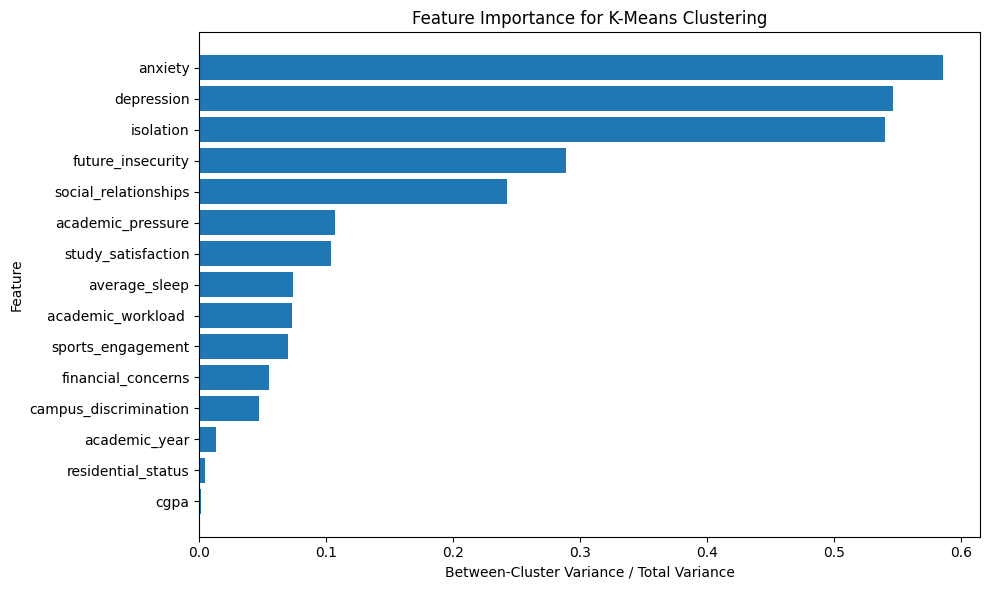

In [14]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Between-Cluster Variance / Total Variance")
plt.ylabel("Feature")
plt.title("Feature Importance for K-Means Clustering")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## **FEATURE ENGINEERING**

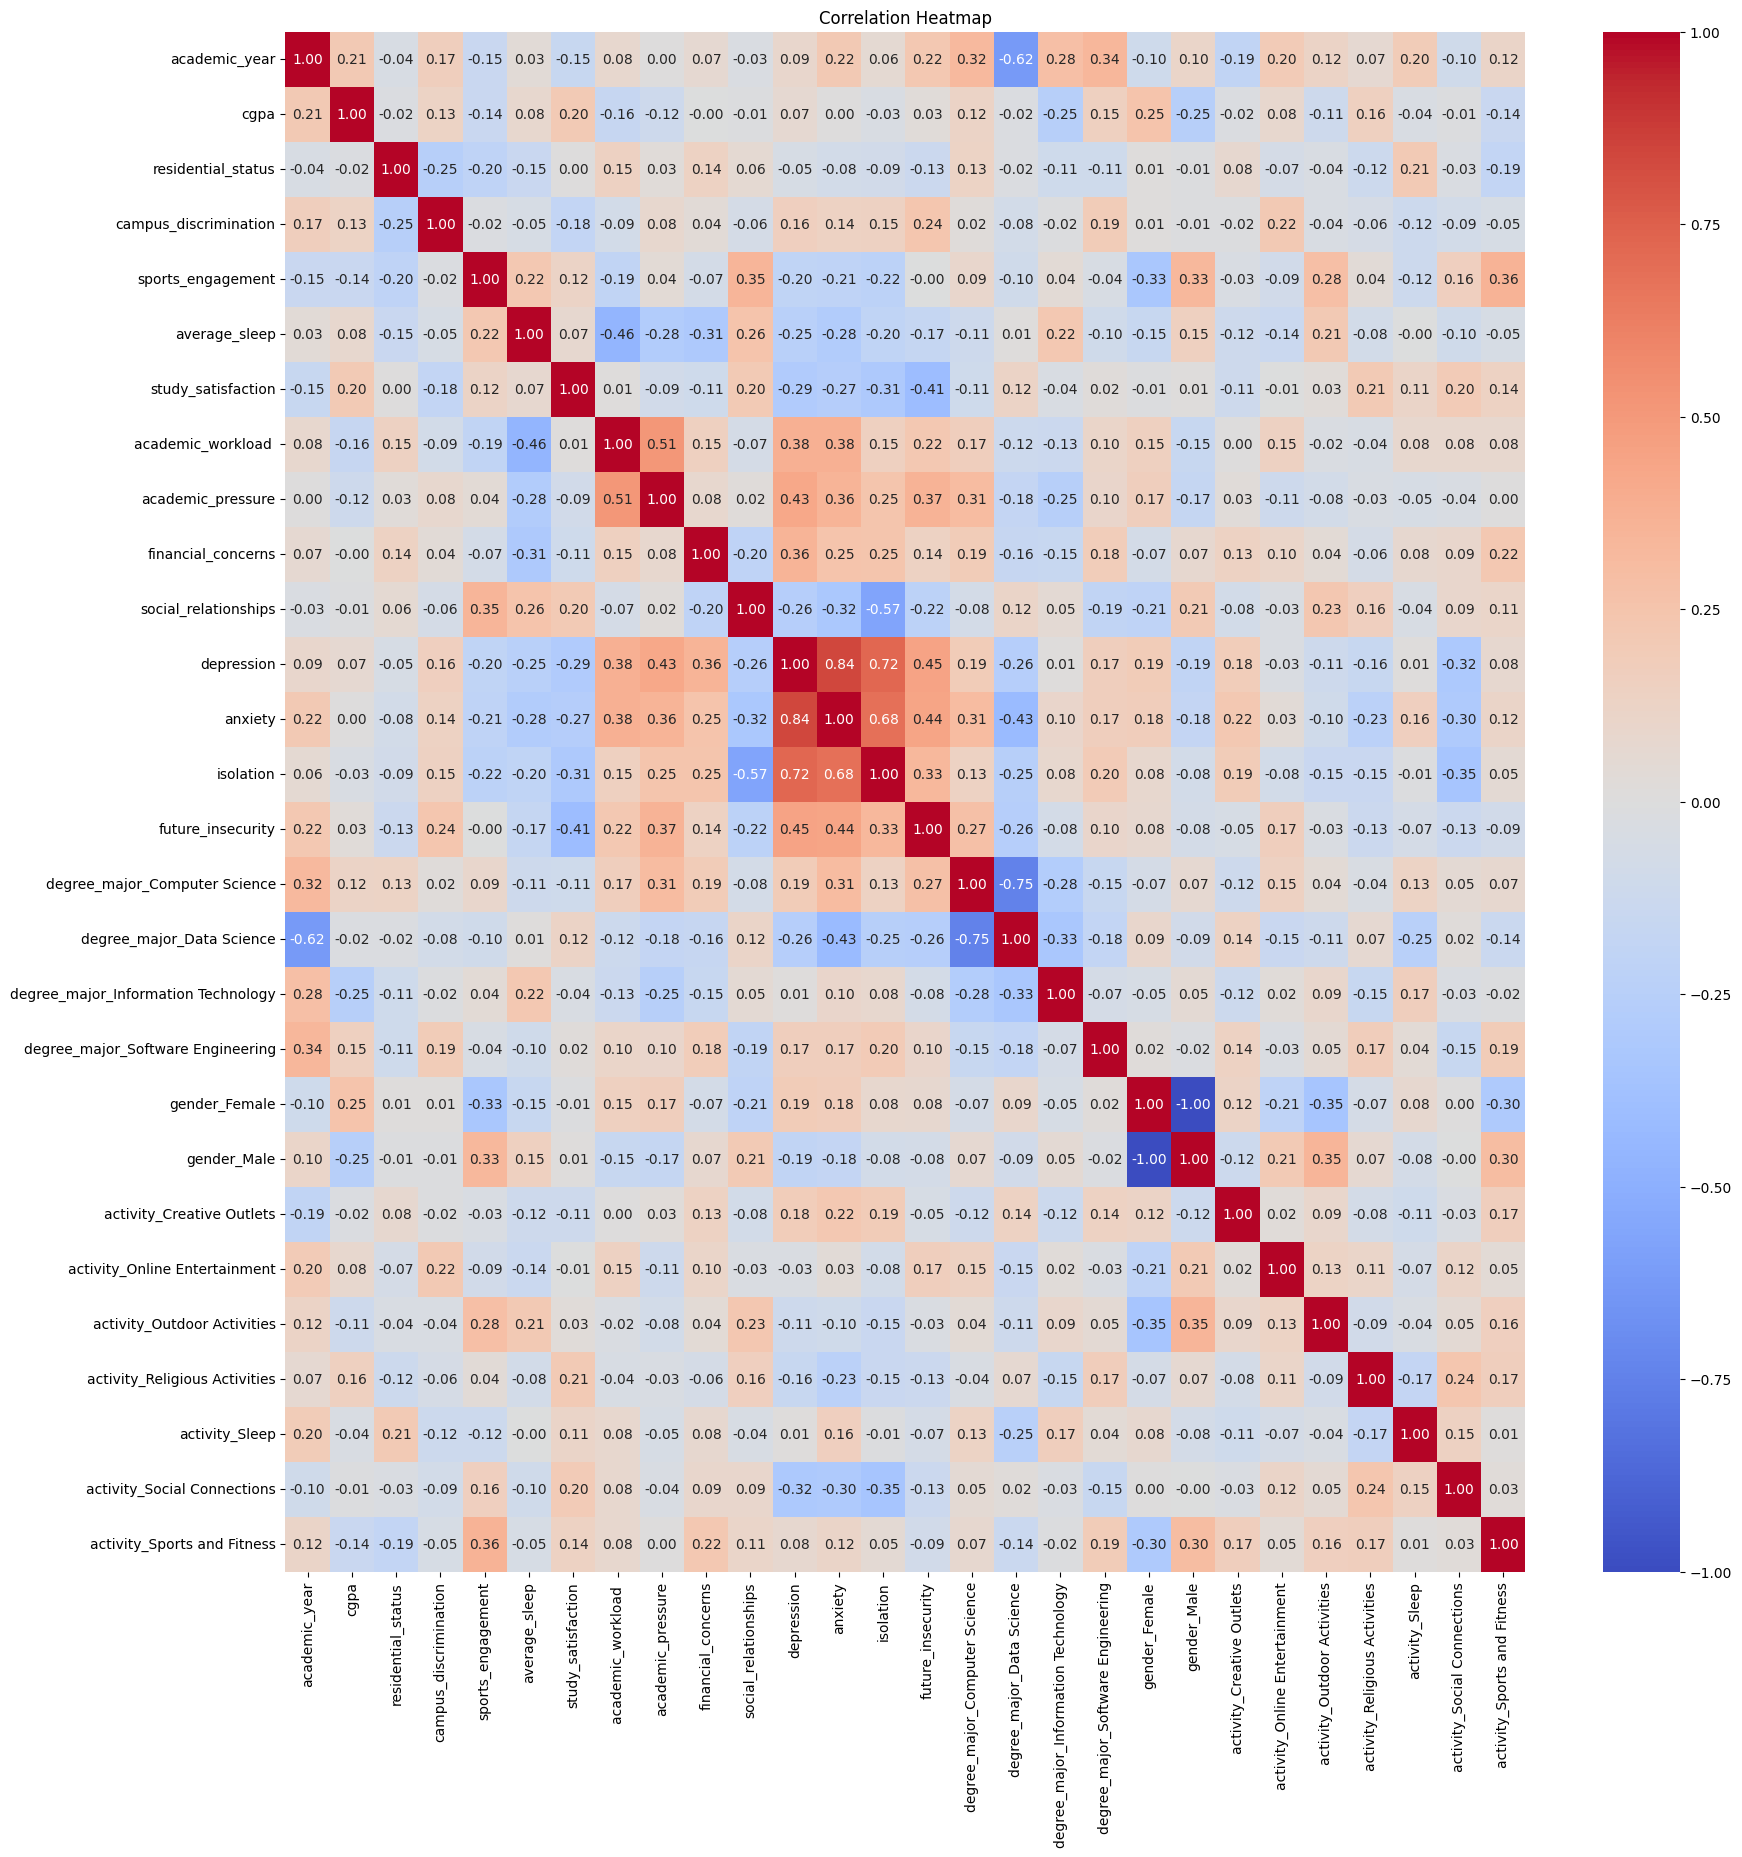

In [15]:
plt.figure(figsize=(20, 20))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### **On Not Scaled**

In [16]:
data_en = df_clean.copy()

# Label encode
gpa_map = {4:5, 3:4, 5:6, 1:2, 2:3, 0:1}
data_en['cgpa'] = data_en['cgpa'].map(gpa_map)

slp_map = {1:2, 0:1, 2:3}
data_en['average_sleep'] = data_en['average_sleep'].map(slp_map)

ayr_map = {1:2, 2:3, 0:1, 3:4}
data_en['academic_year'] = data_en['academic_year'].map(ayr_map)

sports_map = {0:1, 1:2, 3:4, 2:3}
data_en['sports_engagement'] = data_en['sports_engagement'].map(sports_map)

In [17]:
# Remove lowest importance variables
df_fe = data_en.drop(labels=['campus_discrimination', 'residential_status', 'cgpa', 'academic_year'], axis=1)

# Create ratios for:
# 'isolation' and 'social_relationships'
# 'average_sleep' and 'academic_workload'
# 'sports_engagement' and 'social_relationships'
df_fe['social_iso_ratio'] = df_fe['social_relationships']/df_fe['isolation']
df_fe['sleep_work_ratio'] = df_fe['academic_workload ']/df_fe['average_sleep']
df_fe['social_sport_ratio'] = df_fe['social_relationships']/df_fe['sports_engagement']
df_fe['work_pressure_ratio'] = df_fe['academic_workload ']/df_fe['academic_pressure']

# Create scores for:
# 'depression' and 'anxiety'
# 'depression' and 'anxiety' and 'isolation'
df_fe['mental_health_score'] = 0.55*df_fe['depression'] + 0.45*df_fe['anxiety']
df_fe['mental_stressor_score'] = 0.5*df_fe['depression'] + 0.4*df_fe['anxiety'] + 0.1*df_fe['isolation']

# Remove parent variables of new features
df_fe = df_fe.drop(labels=['sports_engagement', 'academic_workload ', 'academic_pressure',
                           'social_relationships', 'depression', 'anxiety', 'isolation'], axis=1)

df_fe.head()
df_fe.to_csv(r"/content/df_fe.csv", index=False)

In [ ]:
np.isinf(df_fe).sum()

,0
average_sleep,0
study_satisfaction,0
financial_concerns,0
future_insecurity,0
degree_major_Computer Science,0
degree_major_Data Science,0
degree_major_Information Technology,0
degree_major_Software Engineering,0
gender_Female,0
gender_Male,0


In [ ]:
df_fe.isnull().sum()

,0
average_sleep,0
study_satisfaction,0
financial_concerns,0
future_insecurity,0
degree_major_Computer Science,0
degree_major_Data Science,0
degree_major_Information Technology,0
degree_major_Software Engineering,0
gender_Female,0
gender_Male,0


### **On Scaled**

In [ ]:
df_num_scaled = pd.read_csv("/content/mental_health_preprocessed.csv")

In [ ]:
data_en = df_num_scaled.copy()

# Label encode
gpa_map = {4:5, 3:4, 5:6, 1:2, 2:3, 0:1}
data_en['cgpa'] = data_en['cgpa'].map(gpa_map)

slp_map = {1:2, 0:1, 2:3}
data_en['average_sleep'] = data_en['average_sleep'].map(slp_map)

ayr_map = {1:2, 2:3, 0:1, 3:4}
data_en['academic_year'] = data_en['academic_year'].map(ayr_map)

sports_map = {0:1, 1:2, 3:4, 2:3}
data_en['sports_engagement'] = data_en['sports_engagement'].map(sports_map)

In [ ]:
# Remove lowest importance variables
df_fe = data_en.drop(labels=['campus_discrimination', 'residential_status', 'cgpa', 'academic_year'], axis=1)

# Create ratios for:
# 'isolation' and 'social_relationships'
# 'average_sleep' and 'academic_workload'
# 'sports_engagement' and 'social_relationships'
df_fe['social_iso_ratio'] = df_fe['social_relationships']/df_fe['isolation']
df_fe['sleep_work_ratio'] = df_fe['academic_workload ']/df_fe['average_sleep']
df_fe['social_sport_ratio'] = df_fe['social_relationships']/df_fe['sports_engagement']
df_fe['work_pressure_ratio'] = df_fe['academic_workload ']/df_fe['academic_pressure']

# Create scores for:
# 'depression' and 'anxiety'
# 'depression' and 'anxiety' and 'isolation'
df_fe['mental_health_score'] = 0.55*df_fe['depression'] + 0.45*df_fe['anxiety']
df_fe['mental_stressor_score'] = 0.5*df_fe['depression'] + 0.4*df_fe['anxiety'] + 0.1*df_fe['isolation']

# Remove parent variables of new features
df_fe = df_fe.drop(labels=['sports_engagement', 'academic_workload ', 'academic_pressure',
                           'social_relationships', 'depression', 'anxiety', 'isolation'], axis=1)

df_fe.head()


In [ ]:
np.isinf(df_fe).sum()

,0
average_sleep,0
degree_major_Computer Science,0
degree_major_Data Science,0
degree_major_Information Technology,0
degree_major_Software Engineering,0
gender_Female,0
gender_Male,0
activity_Creative Outlets,0
activity_Online Entertainment,0
activity_Outdoor Activities,0
